*openmobisim tutorials* · [00 · overview](00_getting_started.ipynb) · ← [02 · Demand](02_demand.ipynb) · [04 · Bikes, walking, transit and the choice of mode](04_multimodal.ipynb) → · [documentation](https://openmobisim.github.io)

# 03 · Car assignment: routes, choice and the iterations

How openmobisim decides which way each driver goes, and how it knows when it is done.

**Terms used here.**
- A **route set** is the handful of routes a trip may take between its origin and destination.
- **Route choice** picks one of them for each traveller. The default is a **logit** model: each route's utility is
  mostly its expected time (minus 0.2 per minute), plus a term that keeps routes sharing most of their links from
  counting twice (path size); a traveller takes the route with the highest utility plus a random term of their own,
  so most take the fastest route and some a nearly-as-fast one.
- The **loading** moves the vehicles through the network second by second and measures the times they really take.
  The default is a **point queue**: every link and junction has a capacity, and a queue forms behind it and delays
  everyone in it, but takes no road space.
- Choice and loading are repeated: after each loading a share of the travellers choose again on the times it
  produced (the **method of successive averages**, `msa`: half after the first loading, a third after the second, …),
  and the route sets grow with the best route on those times. The **gap** measures how much faster the best route was
  than the route taken, on average. Even at equilibrium a logit model sends some travellers down a slower route on
  purpose, so the **disequilibrium** is the gap less what the model itself expects; it is what the stopping rule and
  the **verdict** judge (good below 5%, acceptable below 15%).

**Download** {download}`this notebook <../_static/notebooks/03_car_assignment.ipynb>` or {download}`all ten <../_static/notebooks/openmobisim_notebooks.zip>` (a zip), without their outputs. The Installation section below installs openmobisim; its last command, `openmobisim notebooks`, copies the same ten into a folder and opens the first in JupyterLab.

---

## Installation

> Skip this if `import openmobisim` already works in this notebook. **One install is all there is:**
> `pip install "openmobisim[all]"` brings the simulator and everything the ten tutorials use (JupyterLab,
> matplotlib for the figures, pandas, polars and pyarrow for the tables); nothing is installed later. Find the case
> that matches yours and copy its commands, in order. Each needs Python 3.11 or newer.
>
> **A new conda environment** (any system; openmobisim is on PyPI, so pip installs it into the environment):
>
> ```bash
> conda create -y -n openmobisim python=3.12
> conda activate openmobisim
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on macOS or Linux** (in a terminal):
>
> ```bash
> python3 -m venv openmobisim
> source openmobisim/bin/activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on Windows** (in the Command Prompt):
>
> ```bat
> py -m venv openmobisim
> openmobisim\Scripts\activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> The last line copies these ten notebooks into `./openmobisim-notebooks` and opens them in JupyterLab. In VS Code or
> PyCharm, open a notebook and choose the `openmobisim` environment's Python as its kernel instead.
>
> **Into the environment this notebook already runs in**: paste this into a new code cell, run it, then restart the
> kernel.
>
> ```python
> %pip install "openmobisim[all]"
> ```

---

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import openmobisim as ms
from openmobisim import viz

## 1 · A grid and a busy hour

An 8 × 8 grid of two-way streets, 200 m blocks, one lane each way at 50 km/h, with a signal at every junction. The
demand is **20 000 car trips between random places 0.6–2.5 km apart, leaving at random times over one hour**: a
synthetic load to exercise the model, not a forecast.

In [2]:
net = ms.examples.manhattan_grid(n=8, block_metres=200.0, signals=True)
trips = ms.examples.trips_random(net, 20_000, seed=1, spread_s=3600, min_m=600, max_m=2500)
cars = {"commuter": (True, False, False)}
print(net, len(trips), "trips")


def mean_trip_min(run):
    return run.mean_travel_time_s / 60

Network(64 nodes, 224 links) 20000 trips


## 2 · Free flow and the default run

At **free flow** (`flow_level=0`), with everyone on their fastest route (`choice_model="deterministic"`), no vehicle
delays another: the lower bound. The **default run** loads the network
with queues and iterates until the disequilibrium, averaged over the last three iterations, is below 5% (or ten
loadings).

In [3]:
free = ms.Scenario.from_parts(
    net, trips, classes=cars, flow_level=0, equilibration="free_flow", choice_model="deterministic"
).run("grid-free-flow", output_dir="runs/grid-free-flow", quiet=True)
run = ms.Scenario.from_parts(net, trips, classes=cars, link_bin_s=900).run(
    "grid", output_dir="runs/grid"
)
print(f"mean trip at free flow: {mean_trip_min(free):.2f} min")
print(f"mean trip, default run: {mean_trip_min(run):.2f} min")
print("verdict:", run.convergence_verdict, f"(disequilibrium {run.convergence_gap:.4f})")

Run 'grid': 0.4 s, window 00:00–03:00, 20,000 of 20,000 trips completed, mean trip 3.1 min, verdict good (run.timings() has every stage)


mean trip at free flow: 2.52 min
mean trip, default run: 3.06 min
verdict: good (disequilibrium 0.0225)


## 3 · How the iterations went

`Run.convergence()` has one entry per loading. Iteration 0 is the **free-flow loading**: the travellers are split into
five groups; the first chooses on free-flow times, then the network is loaded with it and the next group chooses on the
times that produced, and so on, so each group sees the congestion of those before it. In iteration *i* after it, a
share 1/(*i* + 1) of everyone chooses again; "changed route" is the share of travellers whose route changed on the way
to that iteration.

In [4]:
c = run.convergence()
table = pd.DataFrame({
    "iteration": c["iteration"],
    "mean trip (min)": c["total_travel_time_s"] / c["completed_people"] / 60,
    "gap": c["gap"],
    "expected by the model": c["gap_expected"],
    "disequilibrium": c["gap_excess"],
    "changed route (%)": 100 * c["changed_share"],
    "routes added": c["routes_added"],
}).set_index("iteration")
table.round(3)

,mean trip (min),gap,expected by the model,disequilibrium,changed route (%),routes added
iteration,,,,,,
0,8.410,1.445,0.015,1.430,NaN,3524
1,3.832,0.420,0.053,0.366,35.195,214
2,3.112,0.115,0.071,0.044,17.625,197
3,3.077,0.097,0.071,0.026,12.240,137
4,3.064,0.090,0.071,0.018,9.575,102


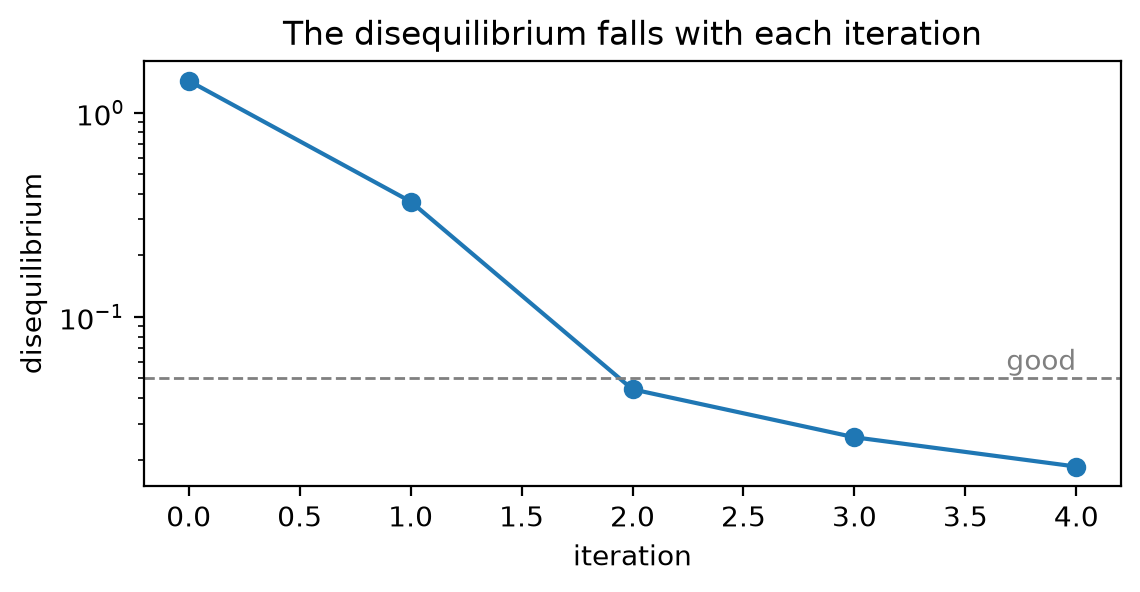

In [5]:
fig, ax = plt.subplots(figsize=(16 / 2.54, 7 / 2.54), dpi=200)
ax.plot(c["iteration"], c["gap_excess"], marker="o")
ax.axhline(0.05, linestyle="--", linewidth=1, color="grey")
ax.text(c["iteration"][-1], 0.055, "good", ha="right", color="grey")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("disequilibrium")
ax.set_title("The disequilibrium falls with each iteration")
plt.show()

The free-flow loading's first groups choose before there is any congestion to avoid, and keep their routes; at the
end of iteration 0 the mean trip is far above the equilibrium's. One iteration in which half the travellers choose
again removes most of it. On a city's network the free-flow loading comes much closer (its routes overlap less than
the grid's many equally short ones), which is why `equilibration="free_flow"`, the free-flow loading alone, is offered
as a quick estimate; on a grid like this one it is not a good one:

In [6]:
quick = ms.Scenario.from_parts(net, trips, classes=cars, equilibration="free_flow").run(
    "grid-quick", output_dir="runs/grid-quick", quiet=True
)
pd.DataFrame(
    {"mean trip (min)": [mean_trip_min(free), mean_trip_min(quick), mean_trip_min(run)]},
    index=["free flow", "free-flow loading alone", "default run (msa)"],
).round(2)

,mean trip (min)
free flow,2.52
free-flow loading alone,8.41
default run (msa),3.06


## 4 · Route sets and choices

A run that iterates starts from **one route per pair** (the fastest at free flow) and lets each iteration add the
fastest route on the times it measured, if it is new: the sets grow where congestion makes other routes worth taking.
`Run.route_choices()` says, for every trip, how many routes it chose among and the probability the model gave the one
it took.

In [7]:
sets = run.route_sets()
print(sets)
choices = run.route_choices()
counts = np.bincount(choices.alternatives)
pd.DataFrame(
    {"trips": counts, "share (%)": 100 * counts / counts.sum()},
    index=pd.Index(range(len(counts)), name="routes to choose among"),
).iloc[1:].round(1)

RouteSets(2808 pairs, 6982 routes, method "shortest")


,trips,share (%)
routes to choose among,,
1,1766,8.8
2,8692,43.5
3,7082,35.4
4,1836,9.2
5,461,2.3
6,132,0.7
7,31,0.2


## 5 · Where the traffic went

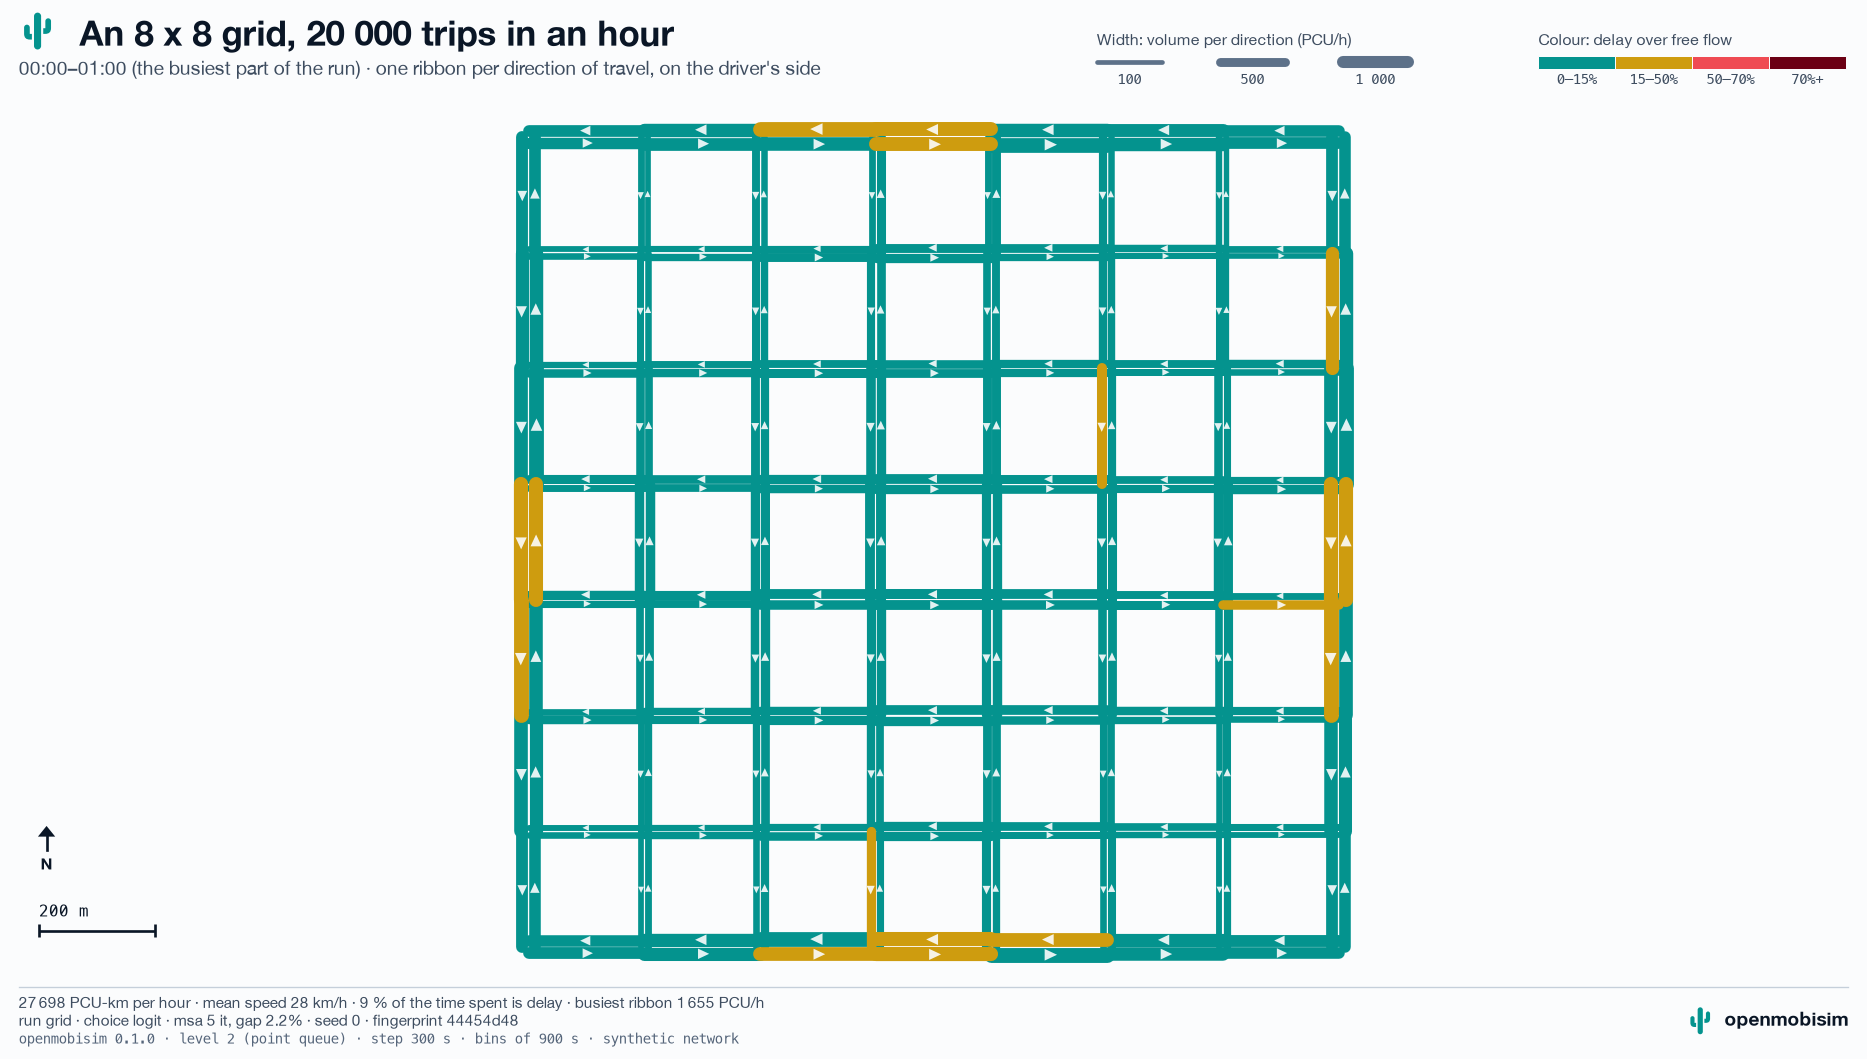

In [8]:
viz.map_link(run, title="An 8 x 8 grid, 20 000 trips in an hour")

## 6 · Other choices of model

**Loading.** `flow_level=4` is the full model: queues take road space and **spill back** onto the links upstream,
with turn pockets and rerouting of vehicles stuck behind a jam. It matters where spillback itself is the subject
(incidents, traffic control). With the point queue, `Run.report_spillback()` lists the links whose queue would not have
fitted on the road, where the point queue's delays are optimistic; here there are none.

**Choice.** `choice_model="deterministic"` sends everyone down the fastest route of their set: useful for debugging,
not for a result to report.

In [9]:
full = ms.Scenario.from_parts(net, trips, classes=cars, flow_level=4).run(
    "grid-full", output_dir="runs/grid-full", quiet=True
)
best = ms.Scenario.from_parts(net, trips, classes=cars, choice_model="deterministic").run(
    "grid-deterministic", output_dir="runs/grid-deterministic", quiet=True
)
print("links whose queue outgrew the road:", len(run.report_spillback()["link"]))
pd.DataFrame(
    {
        "mean trip (min)": [mean_trip_min(r) for r in (run, full, best)],
        "loadings": [len(r.convergence()["gap"]) for r in (run, full, best)],
        "disequilibrium": [r.convergence_gap for r in (run, full, best)],
        "verdict": [r.convergence_verdict for r in (run, full, best)],
    },
    index=["point queue, logit (default)", "full model, logit", "point queue, deterministic"],
).round(4)

links whose queue outgrew the road: 1


,mean trip (min),loadings,disequilibrium,verdict
"point queue, logit (default)",3.0644,5,0.0225,good
"full model, logit",3.1313,5,0.0178,good
"point queue, deterministic",3.2431,10,0.0387,good


Every coefficient, capacity and speed used here is a named default that can be changed by name (notebook 06), and
none is calibrated: they are reasonable starting values, to be replaced by a study's own.

**Next:** [04 · Bikes, walking, transit and the choice of mode](04_multimodal.ipynb): bikes, walking, a timetable, park-and-ride and bike-and-ride, and the choice of mode. The whole series: [00 · overview](00_getting_started.ipynb). The documentation: [openmobisim.github.io](https://openmobisim.github.io). Something wrong or unclear? [Report it](https://github.com/bahmanmdd/openmobisim/issues).